# **Connect to GEE**

In [1]:
!pip install -q --upgrade --pre xee
!pip install -q -U geemap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 56.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 92.7 MB/s eta 0:00:00


In [2]:
import ee

In [3]:
ee.Authenticate()
ee.Initialize(
    project = 'ee-amirhosseinahrari',
    opt_url = 'https://earthengine-highvolume.googleapis.com'
)

# **Study Area**

In [4]:
import geemap

In [5]:
map = geemap.Map(basemap = 'Esri.WorldTopoMap')
map

Map(center=[0, 0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', transp…

In [6]:
point = map.draw_last_feature.geometry()
point

ee.Geometry({
  "functionInvocationValue": {
    "functionName": "Feature.geometry",
    "arguments": {
      "feature": {
        "functionInvocationValue": {
          "functionName": "Feature",
          "arguments": {
            "geometry": {
              "functionInvocationValue": {
                "functionName": "GeometryConstructors.Point",
                "arguments": {
                  "coordinates": {
                    "constantValue": [
                      53.569336,
                      34.307144
                    ]
                  }
                }
              }
            }
          }
        }
      }
    }
  }
})

In [7]:
roi = (
    ee.FeatureCollection("USDOS/LSIB_SIMPLE/2017")
    .filterBounds(point)
    .geometry()
)

In [8]:
map.addLayer(roi, {},'roi')

# **GPM Image Collection**

In [9]:
gpm = (
    ee.ImageCollection("NASA/GPM_L3/IMERG_MONTHLY_V07")
    .filterDate('2000','2025')
    .select('precipitation')
)

In [10]:
gpm

# **to Xarray**

In [11]:
import xarray as xr
from xee import helpers
from shapely.geometry import shape

In [12]:
grid = helpers.fit_geometry(
    geometry = shape(roi.getInfo()),
    grid_crs ='EPSG:4326',
    grid_scale =(0.11, -0.11)
)

In [13]:
ds = xr.open_dataset(
    gpm,
    engine = 'ee',
    **grid
)

In [15]:
ds = ds.sortby('time') * 730.001

# **Clipping**

In [17]:
roi_gdf = geemap.ee_to_gdf(ee.FeatureCollection(roi))

In [20]:
!pip install -q rioxarray
import rioxarray

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 33.9 MB/s eta 0:00:00


In [21]:
ds_clip = ds.rio.clip(roi_gdf.geometry, roi_gdf.crs)

# **Floody Precipitation**

In [26]:
pr_annual = ds_clip.resample(time = 'YE').sum('time')
pr_annual = pr_annual.where(pr_annual > 0)

In [28]:
pr_baseline = pr_annual.mean(dim = 'time')

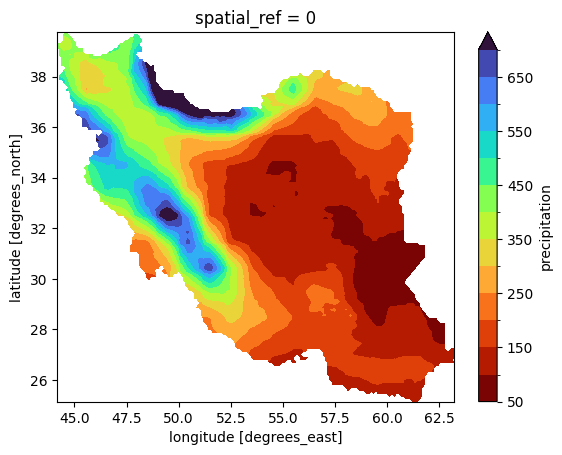

In [31]:
pr_baseline.precipitation.plot.contourf(
    robust =True,
    cmap = 'turbo_r',
    levels = 15
)

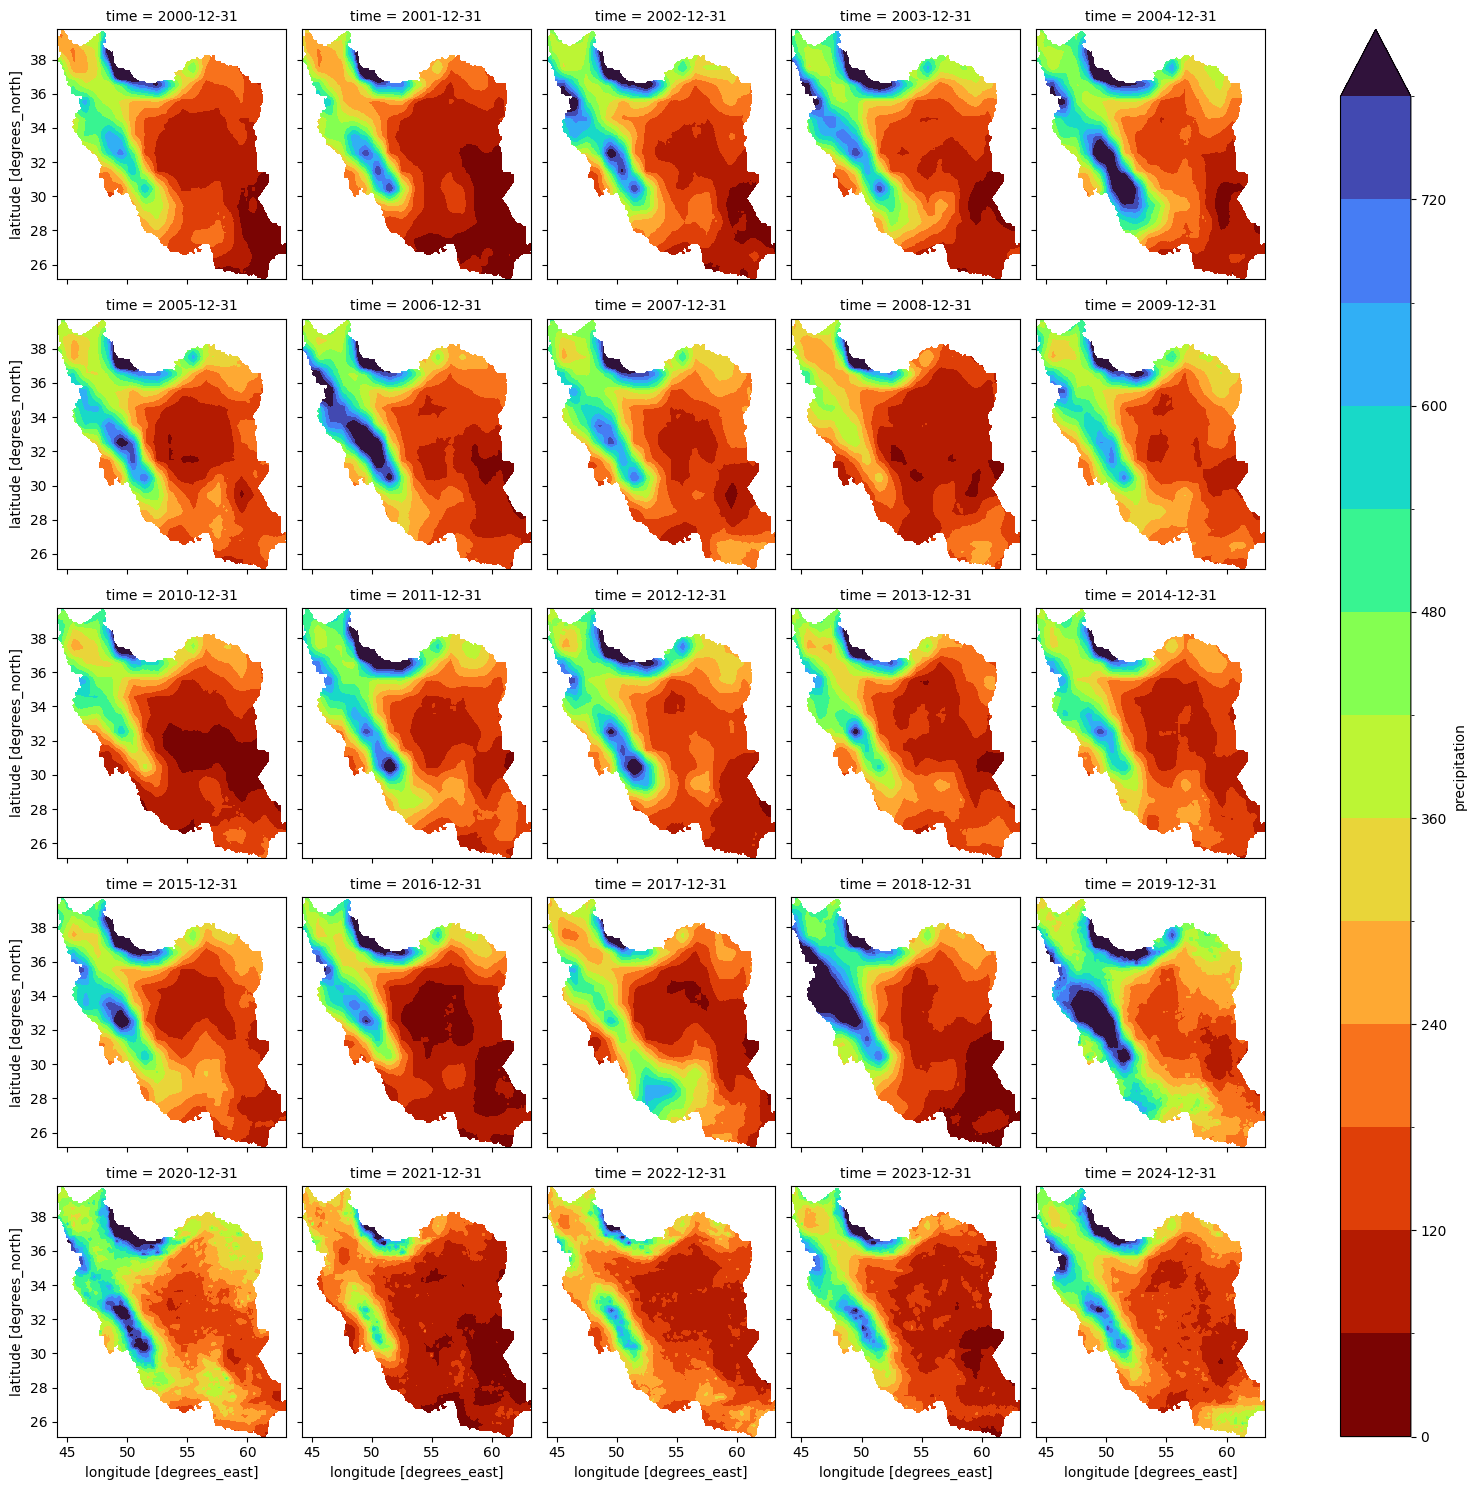

In [32]:
pr_annual.precipitation.plot.contourf(
    robust = True,
    cmap = 'turbo_r',
    col = 'time',
    col_wrap = 5,
    levels = 15
)

In [33]:
pr_anomaly = pr_annual - pr_baseline

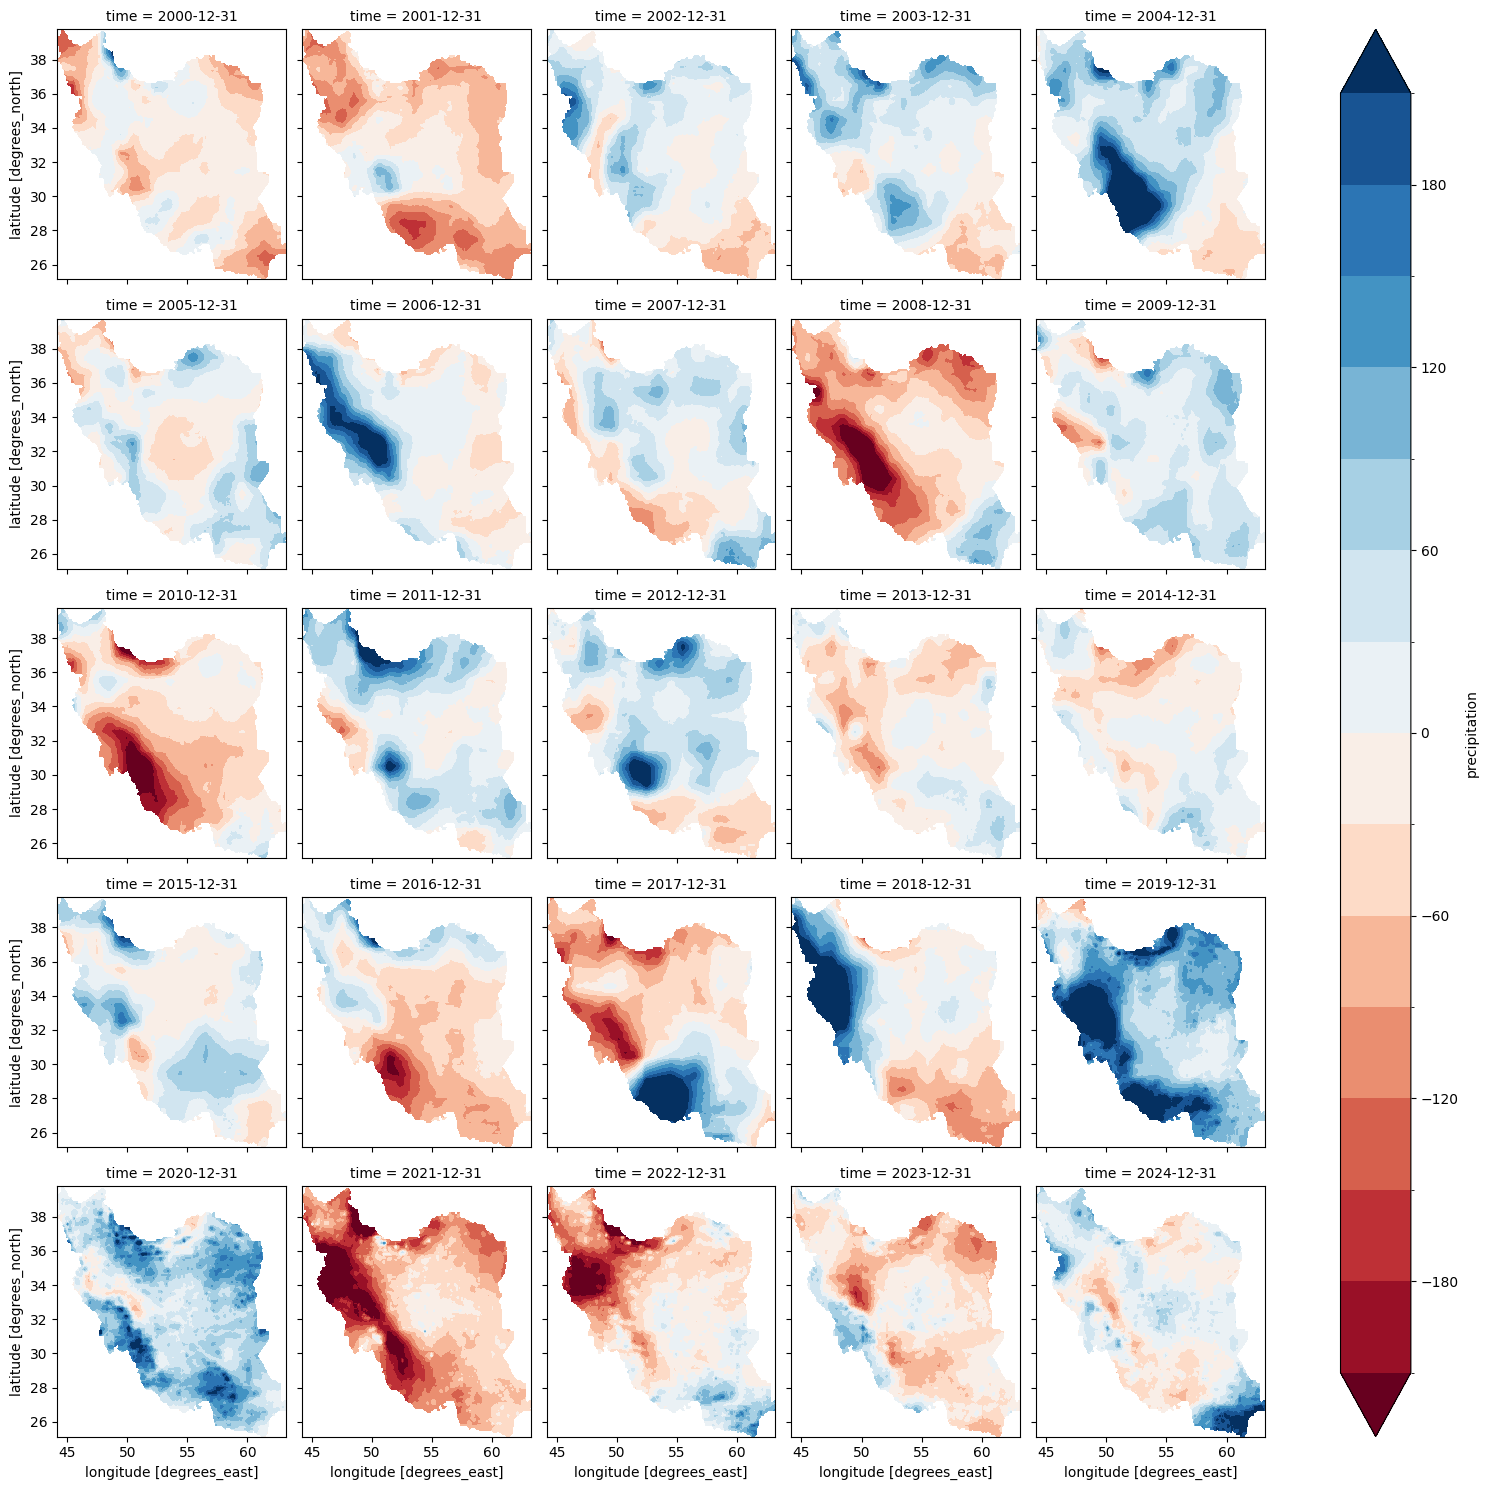

In [34]:
pr_anomaly.precipitation.plot.contourf(
    robust = True,
    cmap = 'RdBu',
    levels =15,
    col = 'time',
    col_wrap = 5
)

In [35]:
anomaly_mean = pr_anomaly.mean(dim = ['x','y'])

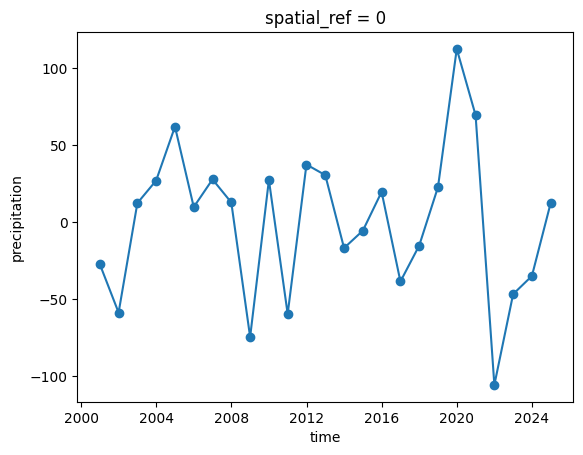

In [38]:
anomaly_mean.precipitation.plot(marker = 'o')

In [39]:
pr_month = ds_clip.groupby('time.month').mean('time')

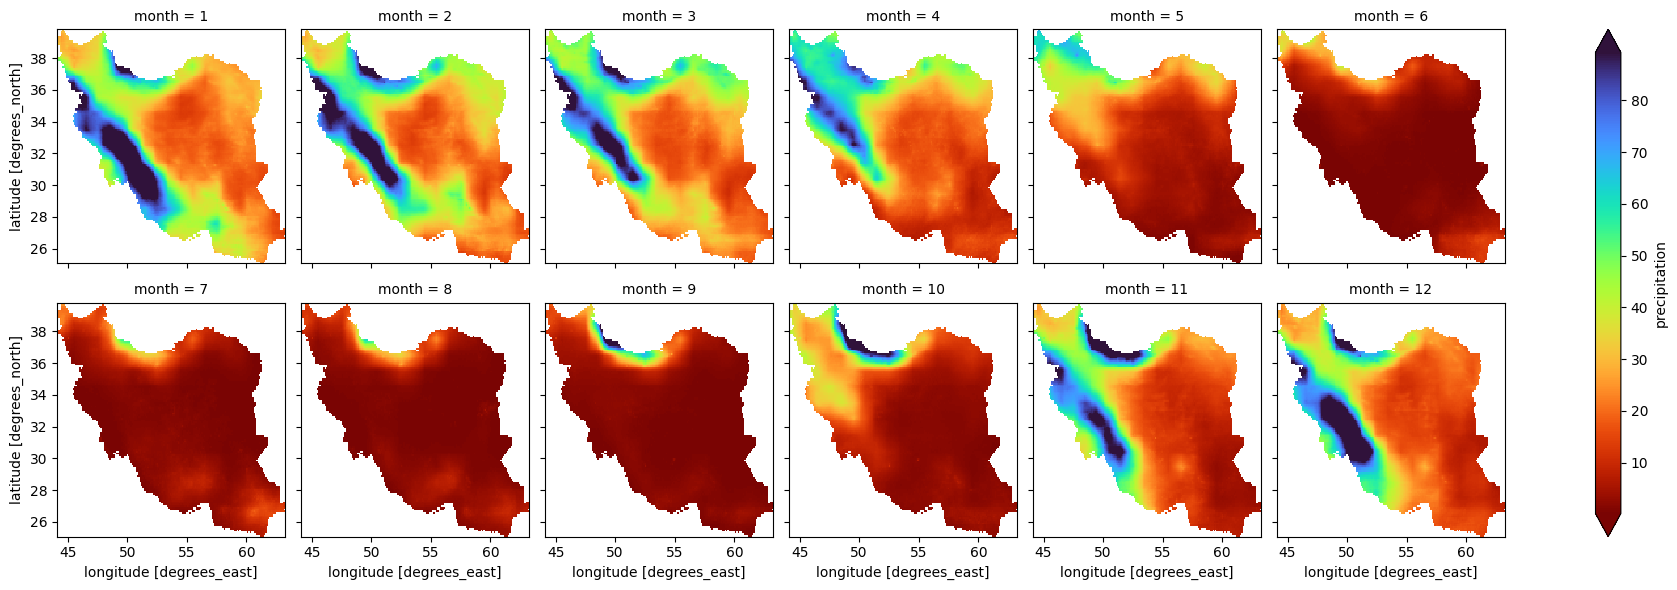

In [41]:
pr_month.precipitation.plot(
    robust = True,
    col = 'month',
    col_wrap = 6,
    cmap = 'turbo_r'
)

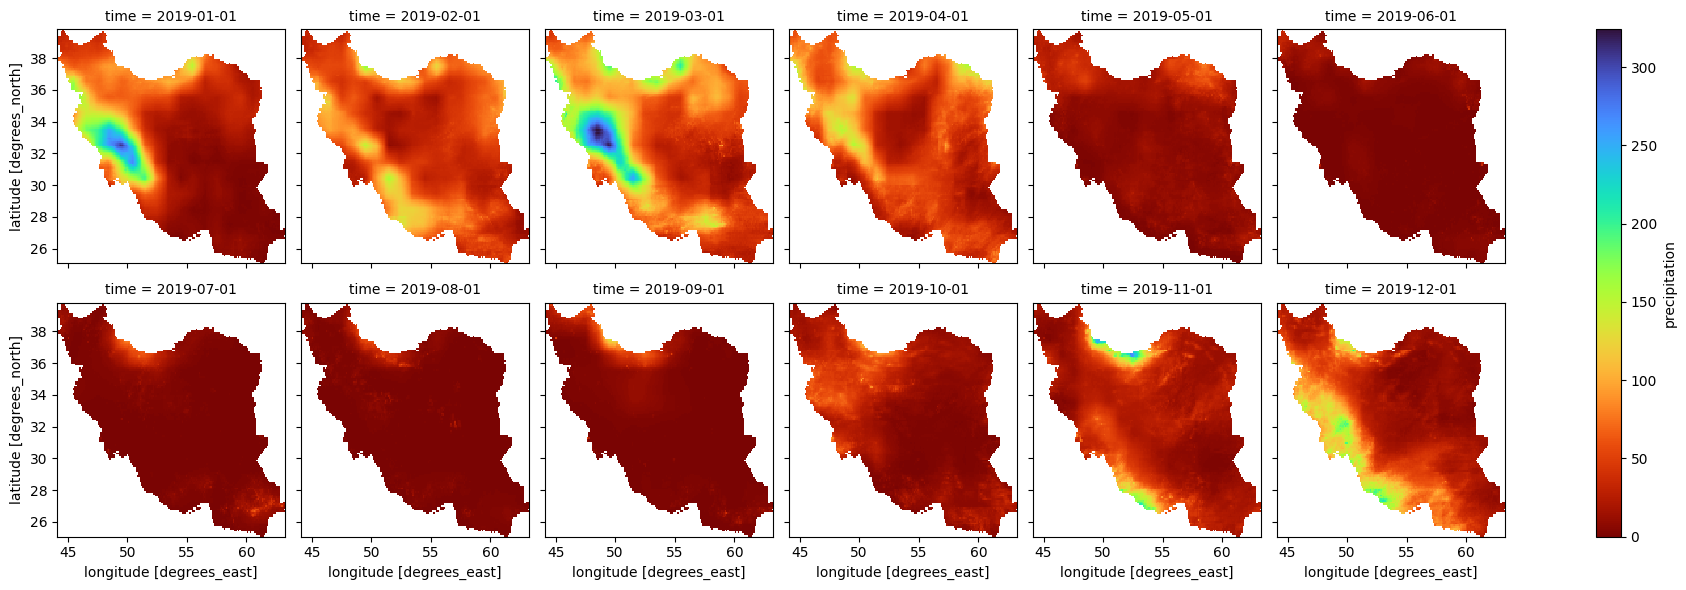

In [43]:
ds_clip.sel(time = '2019').precipitation.plot(
    robust = False,
    cmap = 'turbo_r',
    col = 'time',
    col_wrap = 6
)

In [44]:
ds_clip.sel(time = '2019').precipitation.rio.to_raster('pr_2019.tiff')